# 02 — Models, Bayesian optimisation and HMM (Persons 2 and 3)

This notebook **reads** the outputs of the experiment scripts; it does not retrain. To reproduce from scratch, run in order
(repo root): `python -m src.features.dataset`, `python -m src.models.train_compare`, `python -m src.tuning.bayes_opt 30`,
`python -m src.hmm.evaluate 30`, `python -m src.models.timing`, `python -m src.models.route_eval`,
`python -m src.models.error_analysis`, `python -m src.hmm.break_analysis`.

**Partitions:** train (78 clean trips) for every fit and choice, using GroupKFold(5) by trip; trips 33 and 54 (label-suspect) are reported separately;
student_test (10 trips) is used only to report. The evaluator partition is never read.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
try:
    show                                   # provided by notebooks/make_models_nb.py when it executes this notebook
except NameError:                          # in Jupyter
    from IPython.display import Image, display
    def show(path): display(Image(path))
import pandas as pd, numpy as np, json, yaml
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
from src.features.build import FEATURE_COLUMNS
print(len(FEATURE_COLUMNS), 'features:', ', '.join(FEATURE_COLUMNS))

31 features: dist_m, frac, rank, log_arc_len, zero_len, d_from_node, d_to_node, dist_gap, dist_ratio, n_cands, gap_2nd, cos_c, cos_b, cos_f, abs_cos_c, move_c, speed, dt_prev, dt_next, accel, out_deg_to, in_deg_from, has_twin, prev_same_dist, next_same_dist, prev_conn_dist, next_conn_dist, progress_along, progress_vs_move, win_frac, win_mean_dist


## 1. Dataset for the classifier
One row per (GPS point, candidate arc); label = 1 if the candidate is the reference arc (P1's monotone-DP alignment).

In [2]:
pts = {p: pd.read_parquet(f'data/processed/{p}_points.parquet') for p in ['train', 'student_test']}
F = pd.read_parquet('data/processed/student_test_features.parquet')
for p, d in pts.items():
    c = d[~d.trip_label_suspect]
    print(f"{p:13s} trips={d.trip_id.nunique():3d} points={len(d):7,d} candidate miss rate: all={1-d.label_in_candidates.mean():.4f} clean={1-c.label_in_candidates.mean():.4f}")
print('student_test candidate rows:', f'{len(F):,}', ' positive share:', round(F.label.mean(), 4))
F.groupby('label')[['dist_m', 'cos_c', 'next_conn_dist', 'win_frac', 'speed']].mean()

train         trips= 80 points=208,417 candidate miss rate: all=0.1016 clean=0.0065
student_test  trips= 10 points= 19,160 candidate miss rate: all=0.0009 clean=0.0009
student_test candidate rows: 366,311  positive share: 0.0523


,dist_m,cos_c,next_conn_dist,win_frac,speed
label,,,,,
0,48.3247,-0.0254,44.5909,0.8027,10.9904
1,6.5662,0.7832,6.5618,0.9833,13.7356


The true arcs (label 1) are much closer, aligned with the direction of motion (`cos_c` ≈ +0.8: the **sign** separates the two
directions of a street), and connected to close candidates at the next point.

## 2. Model comparison (Section 3.1)

In [3]:
T = pd.read_csv('results/model_comparison_table.csv')
T

,Model,Algorithm family,Key configuration,"CV macro F1 (5-fold, train)",Student-test top-1 (classifier only),Student-test top-1 (+HMM),Route continuity (classifier only),Route continuity (+HMM),Student-test macro F1,Student-test log loss,Inference time (ms / 1k candidates)
0,Logistic Regression,Linear,"StandardScaler + L2 logistic regression, C=1.0, lbfgs",0.9045 ± 0.0171,0.8410,0.9225,0.9297,0.9836,0.9067,0.0464,0.12
1,Gaussian Naive Bayes,Probabilistic generative,"StandardScaler + Gaussian naive Bayes, var_smoothing=1e-9",0.7441 ± 0.0071,0.7717,0.9163,0.9190,0.9833,0.7376,0.7969,0.30
2,K-Nearest Neighbours,Instance-based,"StandardScaler + KNN, k=25, distance-weighted, 120k-row training subsample",0.8901 ± 0.0193,0.8260,0.9181,0.9183,0.9830,0.8961,0.0577,47.68
3,Random Forest,Bagging ensemble,"300 trees, min_samples_leaf=5, max_features=sqrt",0.9274 ± 0.0174,0.8665,0.9523,0.9391,0.9835,0.9271,0.0347,1.89
4,LightGBM (untuned),Gradient boosting,"LightGBM defaults: 100 trees, lr=0.1, num_leaves=31",0.9245 ± 0.0177,0.8658,0.9582,0.9220,0.9834,0.9265,0.0427,0.33
5,MLP,Neural network,"StandardScaler + MLP (128, 64), ReLU, Adam, early stopping, <=30 epochs, 300k-row subsample",0.9191 ± 0.0162,0.8662,0.9348,0.9439,0.9831,0.9225,0.0376,0.41
6,LightGBM (Bayesian-tuned),Gradient boosting,Optuna TPE best (see Section 4),0.9298,0.8820,0.9627,0.9464,0.9835,0.9327,0.0320,3.66


In [4]:
C = pd.read_csv('results/model_comparison.csv')
C[['model', 'cv_top1_mean', 'cv_top1_std', 'cv_macro_f1_mean', 'cv_log_loss_mean', 'cv_train_top1_mean',
   'test_top1', 'test_macro_f1', 'test_log_loss', 'suspect_trips_top1']].sort_values('cv_top1_mean', ascending=False)

### Per-fold results (fold spread vs model gap)

In [5]:
folds = pd.read_csv('results/model_cv_folds.csv')
folds.pivot(index='fold', columns='model', values='top1').round(4)

model,gaussian_nb,knn,lightgbm,logistic_regression,mlp,random_forest
fold,,,,,,
0,0.7807,0.7702,0.8319,0.7997,0.8218,0.8365
1,0.7783,0.7961,0.8223,0.8106,0.8265,0.8284
2,0.8428,0.8721,0.9093,0.8918,0.9127,0.9232
3,0.8111,0.8309,0.8759,0.8557,0.8748,0.8837
4,0.8252,0.8259,0.8625,0.8433,0.8658,0.8712


Every model finds the same folds hard (fold 2 is easiest for all of them). The fold-to-fold spread (≈ 0.035–0.038) is larger than the
gap between the four best models, so CV alone does not separate RF, LightGBM and MLP (see report 3.4 for the selection argument).

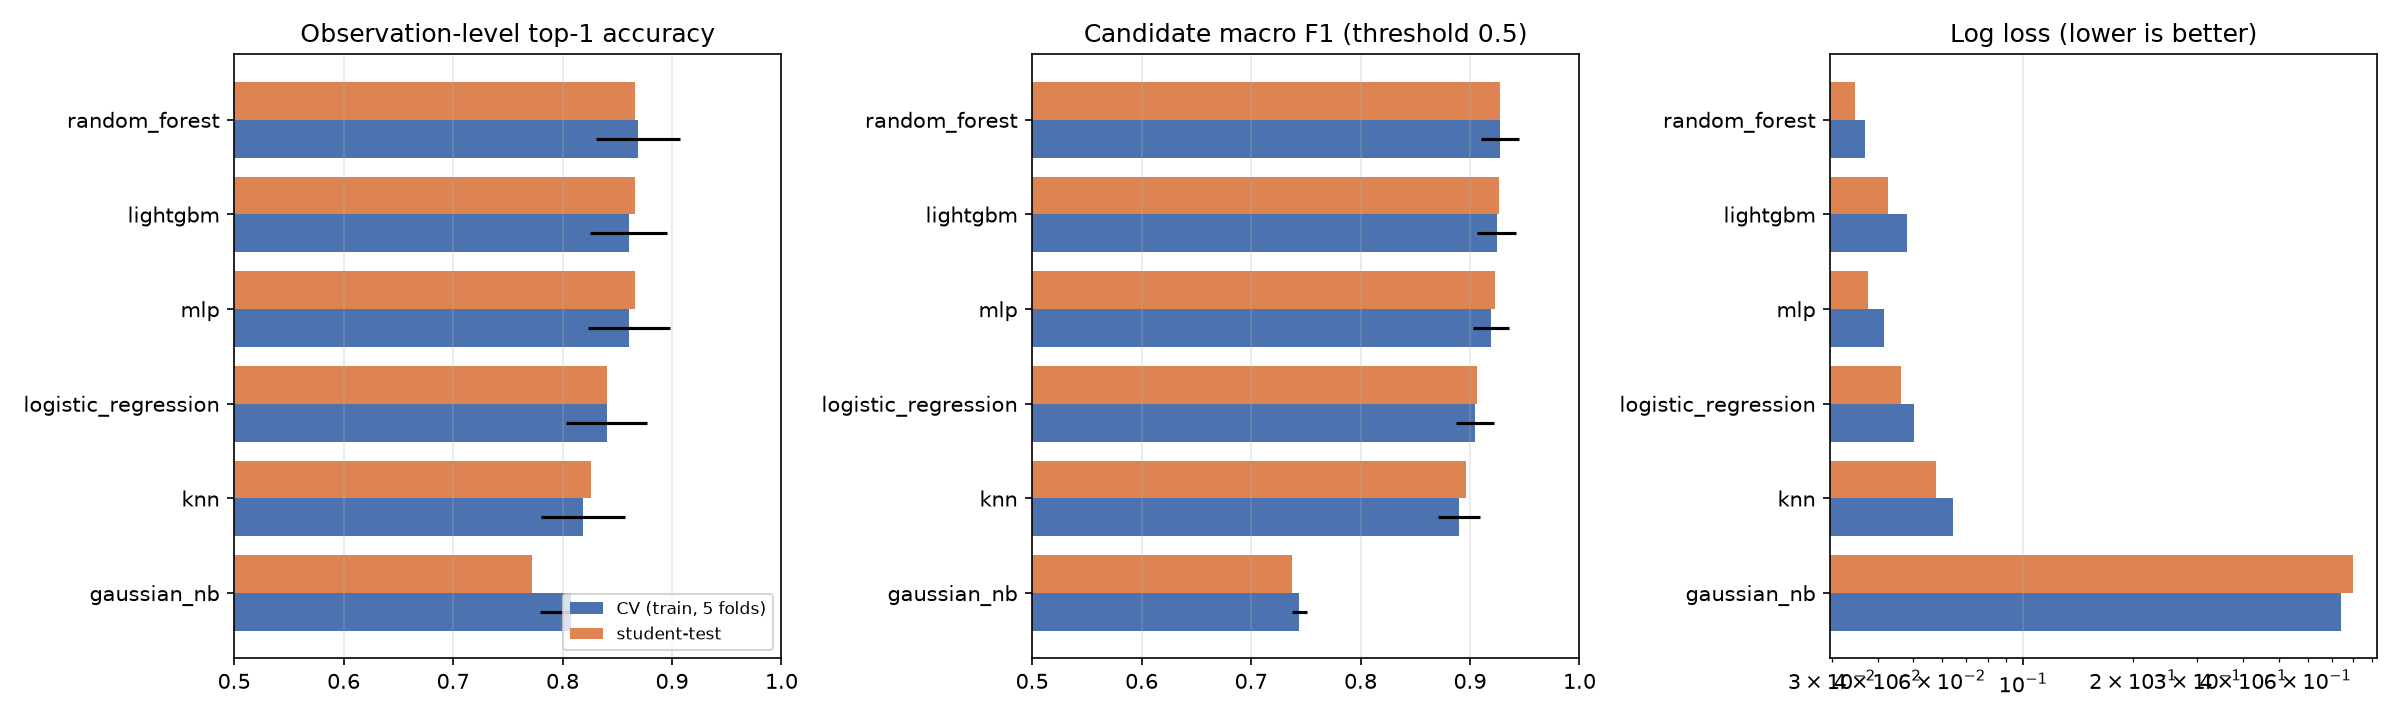

In [6]:
show('results/figures/models_comparison.png')

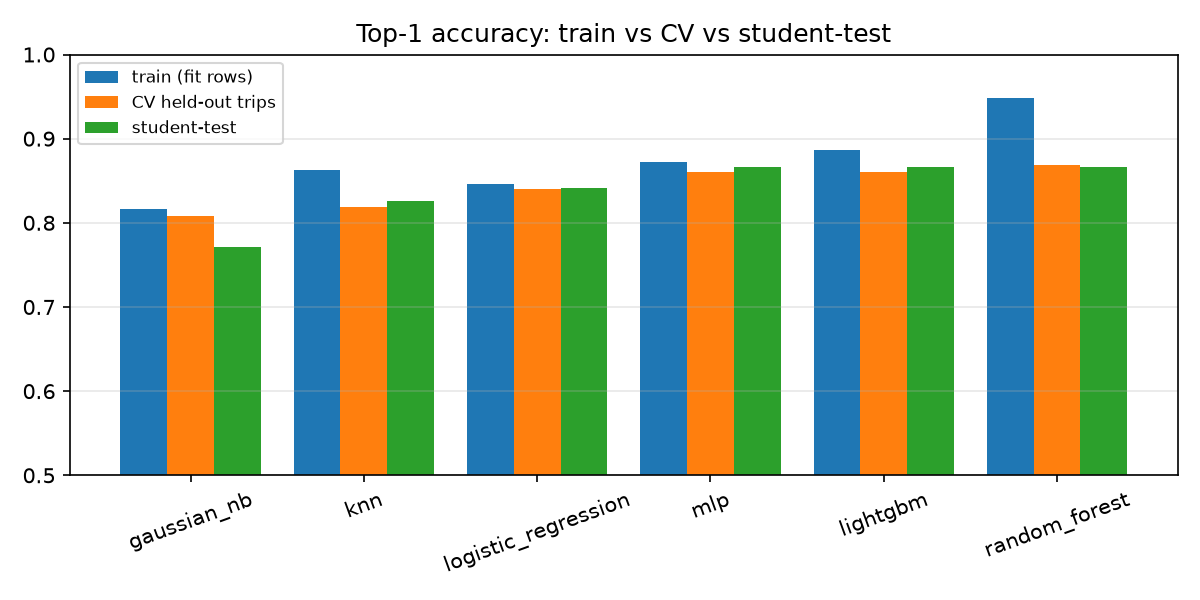

In [7]:
show('results/figures/models_train_cv_test.png')

Train-fit vs CV vs test: Random Forest has the largest gap (0.948 vs 0.869: high variance), logistic regression and naive Bayes
almost none, but they score low (bias).

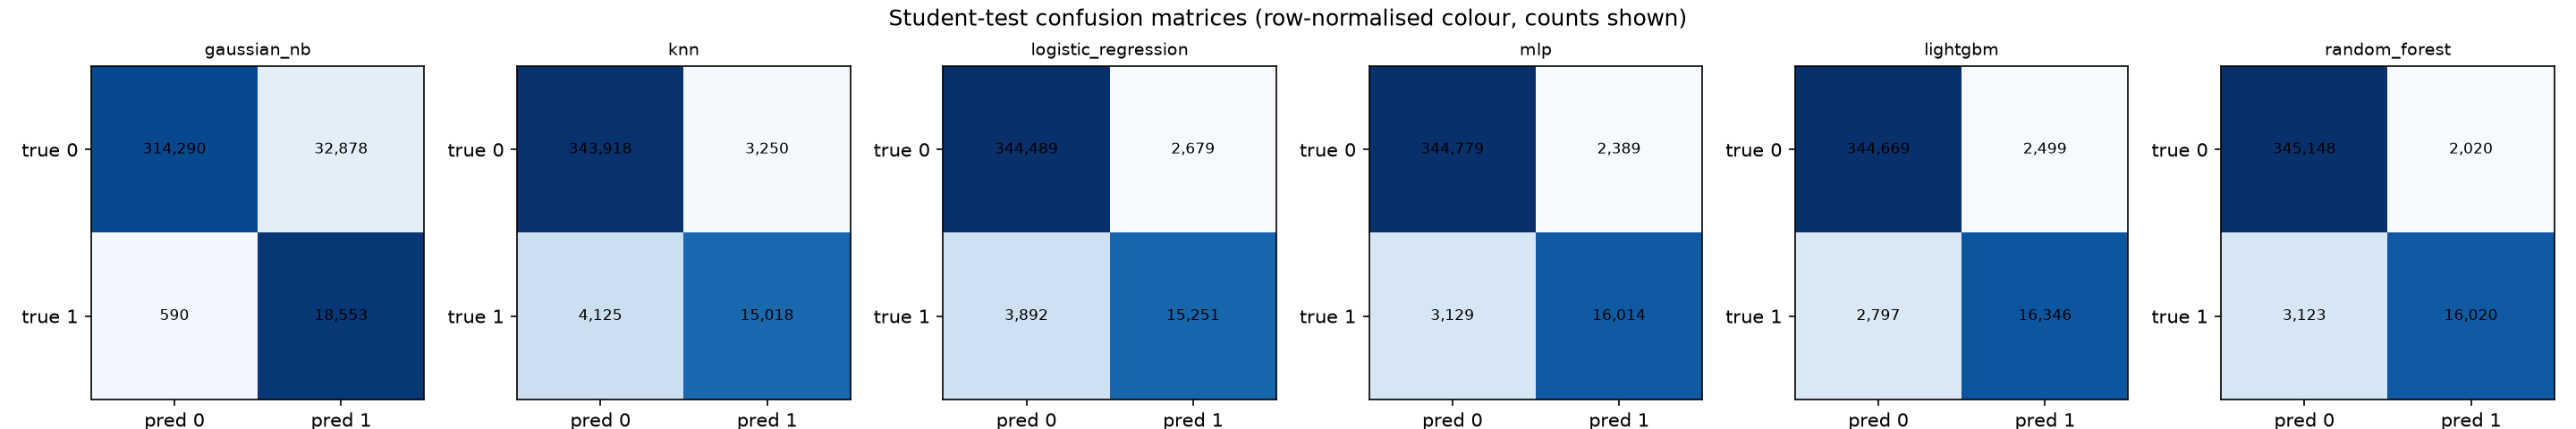

In [8]:
show('results/figures/models_confusion_matrices.png')

Only the MLP has an epoch history, so it is the only model with a loss curve:

best validation accuracy at epoch 14 ; training stopped at epoch 19


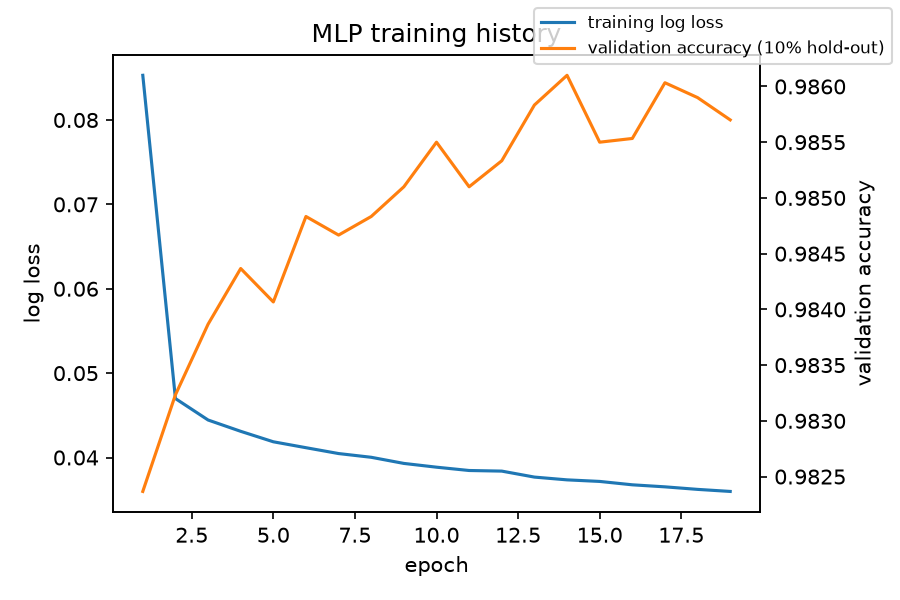

In [9]:
lc = pd.read_csv('results/loss_curve_mlp.csv')
print('best validation accuracy at epoch', int(lc.loc[lc.val_score.idxmax(), 'epoch']), '; training stopped at epoch', int(lc.epoch.max()))
show('results/figures/models_mlp_loss_curve.png')

## 3. Inference time (idle-machine benchmark)

In [10]:
pd.read_csv('results/inference_timing.csv')[['model', 'seconds', 'ms_per_1k_rows', 'model_file_mb']]

,model,seconds,ms_per_1k_rows,model_file_mb
0,logistic_regression,0.0423,0.1154,0.0017
1,gaussian_nb,0.1116,0.3048,0.0020
2,knn,17.4652,47.6786,8.7959
3,random_forest,0.6937,1.8938,74.2887
4,lightgbm,0.1218,0.3326,0.1591
5,mlp,0.1514,0.4132,0.1461
6,lightgbm_tuned,1.3420,3.6635,4.0848


## 4. Bayesian optimisation of LightGBM (Section 4)
Optuna TPE, 30 trials, objective = 3-fold group-CV log loss; trial 0 = the untuned defaults.

In [11]:
tr = pd.read_csv('results/tuning/optuna_trials.csv')
print(tr.state.value_counts().to_dict())
print(json.load(open('results/tuning/best_params.json'))['best_params'])
tr[['number', 'value', 'state', 'user_attrs_top1', 'params_n_estimators', 'params_learning_rate', 'params_num_leaves',
    'params_max_depth', 'params_min_child_samples']].sort_values('value').head(8)

{'COMPLETE': 27, 'PRUNED': 3}
{'n_estimators': 500, 'learning_rate': 0.028950850956799147, 'num_leaves': 194, 'max_depth': 8, 'min_child_samples': 13, 'subsample': 0.5629898215508555, 'colsample_bytree': 0.7403904219080055, 'reg_alpha': 0.08316734057067703, 'reg_lambda': 1.9849750857789579, 'subsample_freq': 1}


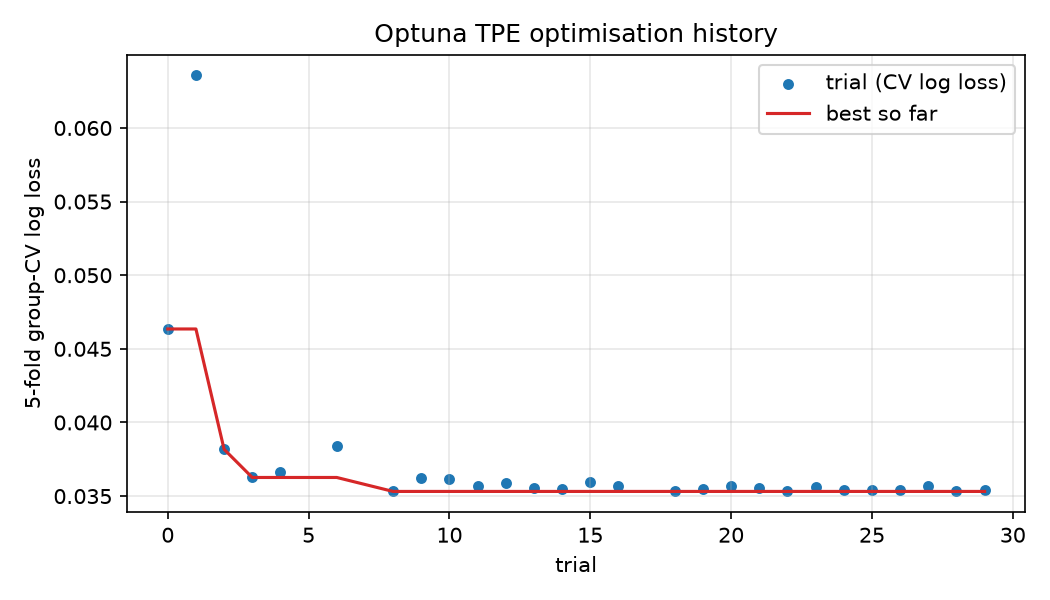

In [12]:
show('results/figures/tuning_history.png')

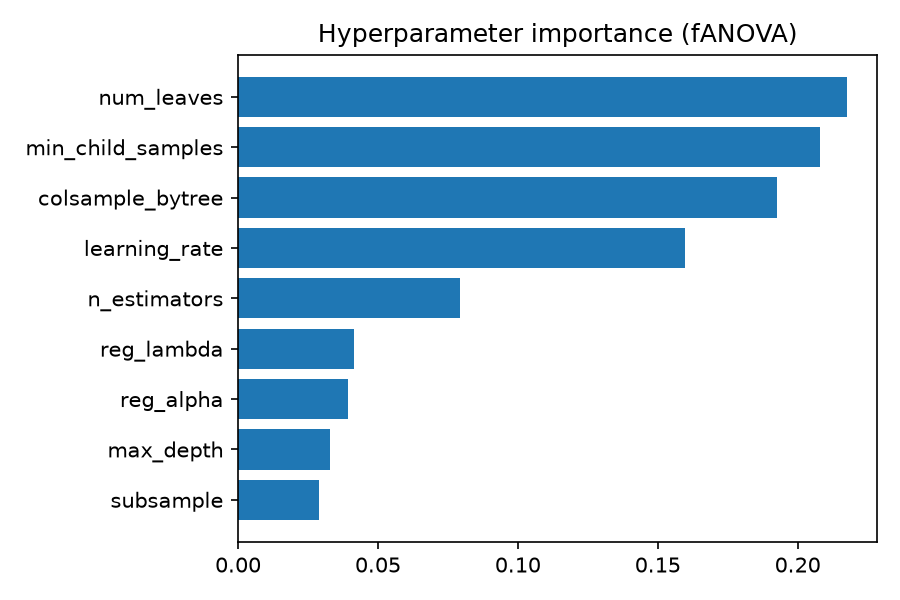

In [13]:
show('results/figures/tuning_importance.png')

In [14]:
pd.read_csv('results/tuning/untuned_vs_tuned.csv').set_index('configuration').T

configuration,untuned (LightGBM defaults),tuned (Optuna TPE)
cv_log_loss,0.0481,0.0351
cv_top1,0.8604,0.8733
cv_macro_f1,0.9245,0.9298
test_top1,0.8658,0.8820
test_macro_f1,0.9265,0.9327
test_log_loss,0.0427,0.0320
test_precision,0.8674,0.8912
test_recall,0.8539,0.8541
train_time_s,12.9946,83.5975
test_inference_s,1.1029,18.8305


## 5. HMM / Viterbi (Section 5)
Decoder parameters tuned on the train out-of-fold probabilities (no student-test involved):

In [15]:
cfg = yaml.safe_load(open('configs/hmm.yaml'))
cfg

{'hmm': {'beta': 5.6801726523799365, 'w_emis': 0.24755938206753822, 'log_floor': -36.93292873658115, 'back_mult': 1.108433717409622, 'min_prob': 1e-06, 'gap_s': 49.62353728862225}, 'tuned_on': '78 clean train trips, 5-fold out-of-fold LightGBM-tuned probabilities', 'objective': 'observation-level top-1', 'train_oof_top1_classifier_only': 0.8532, 'train_oof_top1_hmm_default': 0.9136, 'train_oof_top1_hmm_tuned': 0.9331}

In [16]:
S = pd.read_csv('results/hmm/hmm_vs_classifier_summary.csv')
S

,partition,method,n_trips,n_points,top1 (point-weighted),top1 (trip mean),continuity,breaks / 1k points,edit_distance (trip mean),route_precision,route_recall,route_f1,decode_s_per_1k_points
0,student_test,classifier only,10.0,19160.0,0.8820,0.8931,0.9464,53.6013,0.3602,0.8412,0.9741,0.9010,0.0033
1,student_test,classifier + HMM (default decoder),10.0,19160.0,0.9343,0.9390,0.9835,16.4405,0.1193,0.9433,0.9871,0.9644,0.0223
2,student_test,classifier + HMM (tuned decoder),10.0,19160.0,0.9627,0.9570,0.9835,16.4927,0.0773,0.9585,0.9887,0.9731,0.0264
3,student_test,distance-only HMM (no classifier),10.0,19160.0,0.9288,0.9287,0.9817,18.2672,0.1207,0.9226,0.9809,0.9502,0.0181
4,train (OOF),classifier only,78.0,183260.0,0.8532,0.8771,0.9500,49.9782,0.3567,0.8265,0.9701,0.8869,0.0031
5,train (OOF),classifier + HMM (tuned decoder),78.0,183260.0,0.9331,0.9396,0.9823,17.6689,0.0992,0.9373,0.9832,0.9586,0.0157
6,"train suspect (33, 54)",classifier only,2.0,25157.0,0.1079,0.1389,0.8532,146.7981,0.9245,0.7066,0.9734,0.8185,0.0028
7,"train suspect (33, 54)",classifier + HMM (tuned decoder),2.0,25157.0,0.1295,0.1751,0.9158,84.1913,0.8339,0.8188,0.9809,0.8919,0.0167


In [17]:
D = pd.read_csv('results/hmm/hmm_vs_classifier_per_trip.csv', dtype={'trip_id': str})
D[D.partition == 'student_test'].pivot(index='trip_id', columns='method', values='top1')

method,classifier + HMM (default decoder),classifier + HMM (tuned decoder),classifier only,distance-only HMM (no classifier)
trip_id,,,,
00000000,0.9676,0.9860,0.9473,0.9780
00000007,0.9941,0.9993,0.9365,0.9970
00000009,0.9180,0.9028,0.8713,0.8379
00000040,0.9733,0.9803,0.9419,0.9780
00000052,0.9962,1.0000,0.9618,0.9847
00000056,0.9528,0.9634,0.9012,0.9432
00000065,0.8802,0.8659,0.8398,0.8646
00000076,0.9273,0.9724,0.8896,0.9233
00000077,0.8606,0.9535,0.7591,0.8581


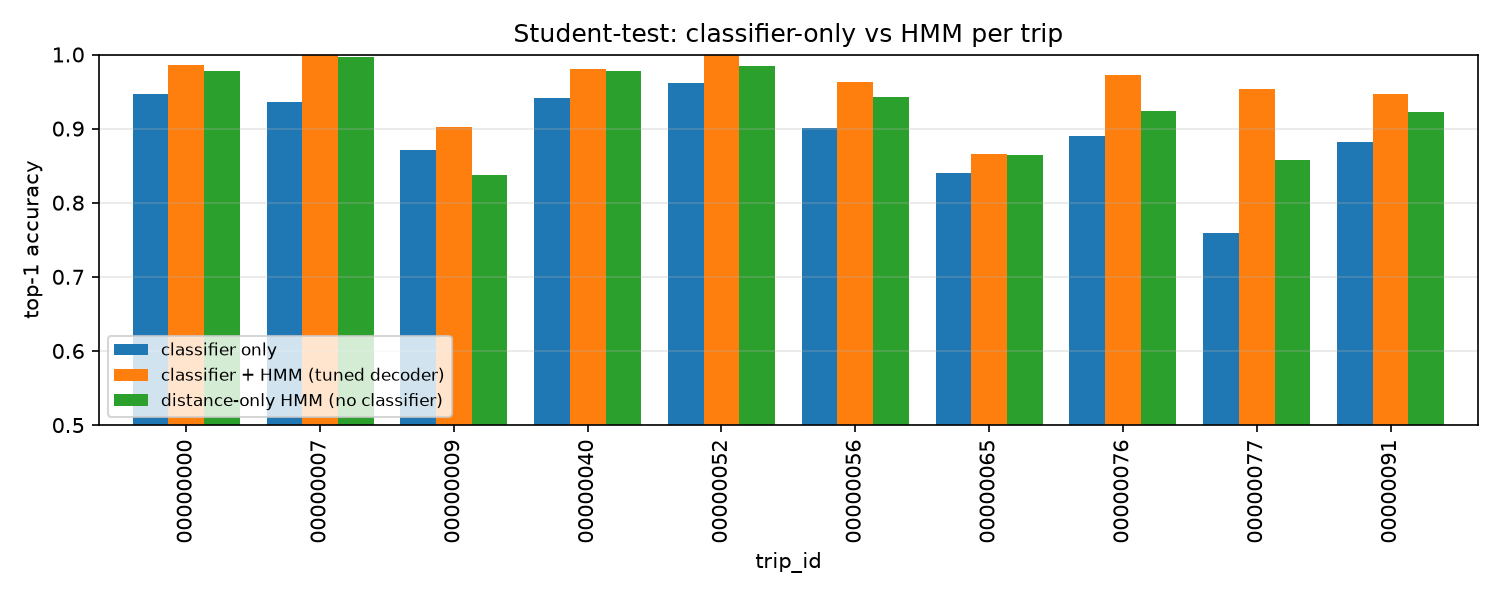

In [18]:
show('results/figures/hmm_vs_classifier_top1.png')

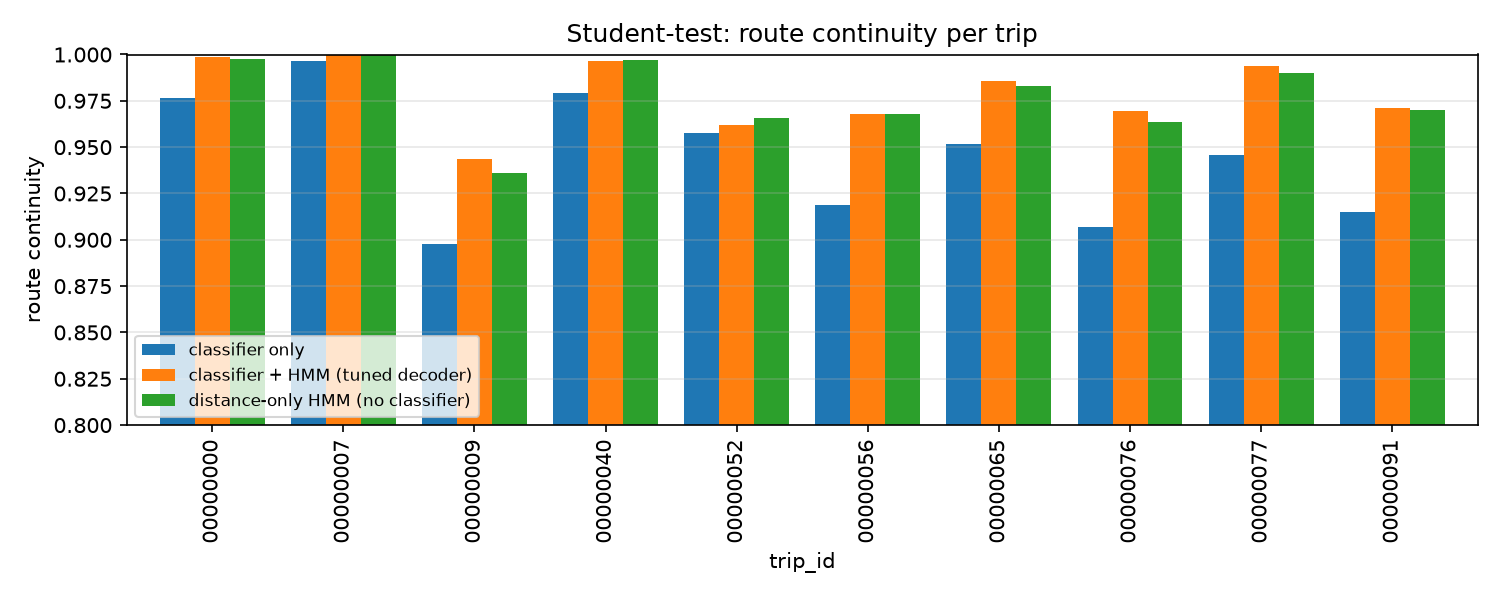

In [19]:
show('results/figures/hmm_vs_classifier_continuity.png')

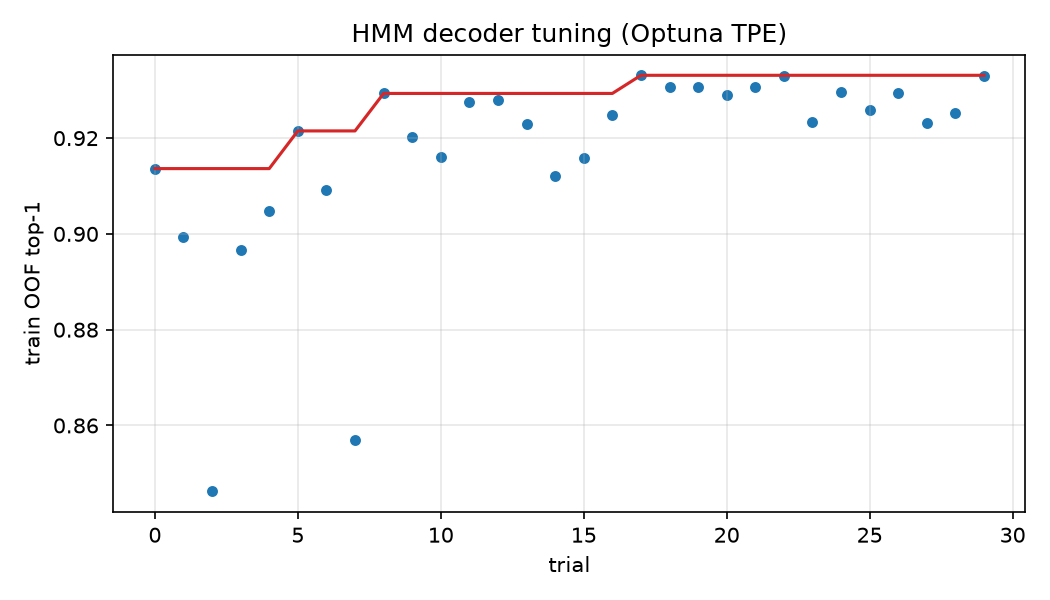

In [20]:
show('results/figures/hmm_decoder_tuning.png')

### What kind of errors does the HMM fix?

In [21]:
pd.read_csv('results/error_analysis.csv').set_index('method').T

method,classifier only,classifier + HMM
n_points,19160.0000,19160.0000
error_rate,0.1180,0.0373
error_rate_slow(<2m/s),0.3874,0.1245
error_rate_moving,0.1063,0.0335
share_of_points_reverse twin,0.0520,0.0130
share_of_points_adjacent arc,0.0191,0.0145
share_of_points_no candidate,0.0000,0.0000
share_of_points_other,0.0469,0.0099


### Are the remaining continuity breaks real jumps?

In [22]:
pd.read_csv('results/hmm/break_analysis.csv')

,trip_id,n_points,breaks,multi-hop (path <= 300 m)
0,00000000,2503,4,4.0
1,00000007,1354,0,0.0
2,00000009,1049,59,59.0
3,00000040,2995,11,11.0
4,00000052,262,10,10.0
5,00000056,3958,126,126.0
6,00000065,768,11,11.0
7,00000076,1486,45,45.0
8,00000077,3911,25,25.0
9,00000091,874,25,25.0


All remaining breaks are multi-hop: a directed road path of ≤ 300 m joins the two arcs (the vehicle crossed short arcs within
one GPS interval). The decoded route is connected on the road graph; the continuity metric (same or directly adjacent arc) is strict.

## 6. Every model through the final decoder

In [23]:
pd.read_csv('results/model_route_metrics.csv').sort_values('hmm_top1', ascending=False)

,model,clf_top1,clf_continuity,hmm_top1,hmm_continuity,clf_edit_distance,hmm_edit_distance
3,lightgbm_tuned,0.8820,0.9464,0.9627,0.9835,0.3602,0.0773
2,lightgbm,0.8658,0.9220,0.9582,0.9834,0.4041,0.0770
6,random_forest,0.8665,0.9391,0.9523,0.9835,0.3834,0.0832
5,mlp,0.8662,0.9439,0.9348,0.9831,0.3737,0.0856
4,logistic_regression,0.8410,0.9297,0.9225,0.9836,0.4048,0.0979
1,knn,0.8260,0.9183,0.9181,0.9830,0.4201,0.1021
0,gaussian_nb,0.7717,0.9190,0.9163,0.9833,0.4402,0.1214


## 7. End-to-end API latency (same code as `POST /predict`)

In [24]:
lat = pd.read_csv('results/api_latency.csv', dtype={'trip_id': str})
print('mean total', round(lat.total_ms.mean()), 'ms; max', lat.total_ms.max(), 'ms')
lat

mean total 680 ms; max 1504 ms


,trip_id,n_points,candidates_ms,classifier_ms,hmm_ms,total_ms
0,00000000,2503,25,302,101,455
1,00000007,1354,35,176,28,255
2,00000009,1049,28,307,160,513
3,00000040,2995,31,365,125,546
4,00000052,262,7,50,25,95
5,00000056,3958,80,884,513,1504
6,00000065,768,47,313,115,492
7,00000076,1486,67,550,313,963
8,00000077,3911,61,938,479,1497
9,00000091,874,23,328,114,484
